# Task 1: Concepts, Splits and Leakage

In [40]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, 
                             confusion_matrix, roc_auc_score, roc_curve, precision_recall_curve,
                             mean_absolute_error, root_mean_squared_error, r2_score)

from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from xgboost import XGBClassifier

In [41]:
np.random.seed(42)
n = 1000

data = {
    'income': np.random.exponential(scale=50000, size=n),
    'loan_amount': np.random.exponential(scale=200000, size=n),
    'credit_score': np.random.normal(650, 50, size=n),
    'application_date': pd.date_range('2023-01-01', periods=n, freq='D'),
    'education': np.random.choice(['High School', 'Bachelor', 'Master'], size=n),
    'property_type': np.random.choice(['Urban', 'Semi-Urban', 'Rural'], size=n),
}

df = pd.DataFrame(data)

df.loc[np.random.choice(n, 30), 'income'] = np.nan
df.loc[np.random.choice(n, 20), 'property_type'] = np.nan

df['default'] = (df['loan_amount'] / (df['income'].fillna(50000) + 1) > 3.5).astype(int)
df.head()

,income,loan_amount,credit_score,application_date,education,property_type,default
0,23463.404499,40946.056383,606.100871,2023-01-01,Master,Rural,0
1,150506.071546,156133.969230,608.655982,2023-01-02,Master,Rural,0
2,65837.284677,412628.358856,638.676055,2023-01-03,Bachelor,Urban,1
3,45647.127689,263521.555826,668.368275,2023-01-04,Master,Rural,1
4,8481.243523,328558.765215,695.679231,2023-01-05,Bachelor,Semi-Urban,1


Depth 1: train 0.58 val 0.53 Depth 3: train 0.60 val 0.55 Depth 5: train 0.63 val 0.54 Depth 10: train 0.73 val 0.53 Depth None: train 1.00 val 0.46


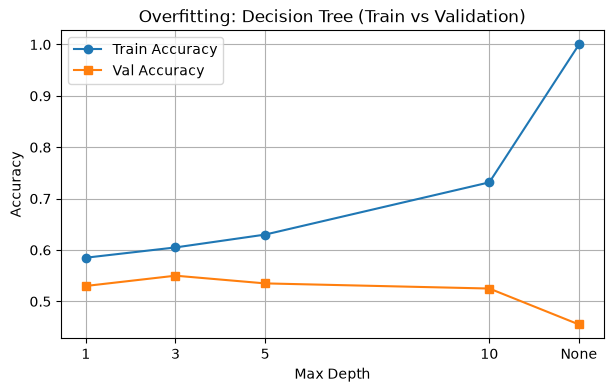

CV: 0.53 +/- 0.03

[Leaky] Scaler Mean (Full data before split): 650.65
[Correct] Scaler Mean (Train set only): 649.64

Data Leakage Explanation:
1. Fitting a scaler before splitting leaks validation/test distribution into training.
2. This creates overly optimistic performance estimates during model evaluation.
3. The correct way is to fit on the training set only, then transform val/test sets.
4. This ensures robust generalization to unseen production data.


Problem Classification:
1. Spam Detection: Supervised Classification
2. Customer Segmentation: Unsupervised Clustering
3. House Price Prediction: Supervised Regression
4. Anomaly Detection: Unsupervised / Semi-supervised

7-Step ML Workflow:
Step 1: Problem Definition & Metric Selection
Step 2: Data Collection & Cleaning
Step 3: Exploratory Data Analysis & Feature Engineering
Step 4: Train / Validation / Test Splitting
Step 5: Model Selection & Baseline Training
Step 6: Hyperparameter Tuning & Cross-Validation
Step 7: Final Test

In [42]:
# 1. Split into train, val, test (60/20/20, stratified)
X = df.drop(columns=['default'])
y = df['default']

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.25, random_state=42, stratify=y_train_full
)

# 2. Decision Tree overfitting with depth variation
depths = [1, 3, 5, 10, None]
train_acc, val_acc = [], []
X_tr_s = X_train[['credit_score']].fillna(650)
X_v_s = X_val[['credit_score']].fillna(650)

output_str = []
for d in depths:
    clf = DecisionTreeClassifier(max_depth=d, random_state=42)
    clf.fit(X_tr_s, y_train)
    tr = clf.score(X_tr_s, y_train)
    vl = clf.score(X_v_s, y_val)
    train_acc.append(tr)
    val_acc.append(vl)
    d_label = str(d) if d is not None else "None"
    output_str.append(f"Depth {d_label}: train {tr:.2f} val {vl:.2f}")

print(" ".join(output_str))

# Plot train vs val accuracy
plt.figure(figsize=(7, 4))
plt.plot([1, 3, 5, 10, 12], train_acc, marker='o', label='Train Accuracy')
plt.plot([1, 3, 5, 10, 12], val_acc, marker='s', label='Val Accuracy')
plt.xticks([1, 3, 5, 10, 12], ['1', '3', '5', '10', 'None'])
plt.xlabel('Max Depth')
plt.ylabel('Accuracy')
plt.title('Overfitting: Decision Tree (Train vs Validation)')
plt.legend()
plt.grid(True)
plt.show()

# 3. 5-fold cross_val_score on LogisticRegression
cv_scores = cross_val_score(LogisticRegression(), X_tr_s, y_train, cv=5)
print(f"CV: {cv_scores.mean():.2f} +/- {cv_scores.std():.2f}")

# 4. Data Leakage demonstration
scaler_bad = StandardScaler().fit(df[['credit_score']])
print("\n[Leaky] Scaler Mean (Full data before split):", round(scaler_bad.mean_[0], 2))

scaler_good = StandardScaler().fit(X_tr_s)
print("[Correct] Scaler Mean (Train set only):", round(scaler_good.mean_[0], 2))

print("""
Data Leakage Explanation:
1. Fitting a scaler before splitting leaks validation/test distribution into training.
2. This creates overly optimistic performance estimates during model evaluation.
3. The correct way is to fit on the training set only, then transform val/test sets.
4. This ensures robust generalization to unseen production data.
""")

# 5. Problem Classification & 7-Step ML Workflow
print("""
Problem Classification:
1. Spam Detection: Supervised Classification
2. Customer Segmentation: Unsupervised Clustering
3. House Price Prediction: Supervised Regression
4. Anomaly Detection: Unsupervised / Semi-supervised

7-Step ML Workflow:
Step 1: Problem Definition & Metric Selection
Step 2: Data Collection & Cleaning
Step 3: Exploratory Data Analysis & Feature Engineering
Step 4: Train / Validation / Test Splitting
Step 5: Model Selection & Baseline Training
Step 6: Hyperparameter Tuning & Cross-Validation
Step 7: Final Test Evaluation & Deployment
""")

# Task 2: Preprocessing, Features and Pipeline

In [43]:
# 1. Feature Engineering: Create at least 3 new features
def create_engineered_features(data_df):
    df_feat = data_df.copy()
    # Feature 1: Date decomposition (Year, Month, Day)
    df_feat['app_year'] = pd.to_datetime(df_feat['application_date']).dt.year
    df_feat['app_month'] = pd.to_datetime(df_feat['application_date']).dt.month
    df_feat['app_day'] = pd.to_datetime(df_feat['application_date']).dt.day
    df_feat.drop(columns=['application_date'], inplace=True)
    
    # Feature 2: Interaction feature (income / loan_amount)
    df_feat['income_to_loan'] = df_feat['income'] / (df_feat['loan_amount'] + 1)
    
    # Feature 3: Log transform for skewed column
    df_feat['log_loan_amount'] = np.log1p(df_feat['loan_amount'])
    
    return df_feat

# Apply feature engineering to splits
X_train_fe = create_engineered_features(X_train)
X_val_fe = create_engineered_features(X_val)
X_test_fe = create_engineered_features(X_test)

# Define column groupings
num_cols_simple = ['credit_score', 'app_year', 'app_month', 'app_day', 'log_loan_amount']
num_cols_knn = ['income', 'income_to_loan', 'loan_amount']
cat_ordered = ['education']
cat_nominal = ['property_type']

# 2. Imputation, Scaling, and Encoding Pipelines
numeric_simple_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

numeric_knn_pipeline = Pipeline([
    ('imputer', KNNImputer(n_neighbors=5)),
    ('scaler', StandardScaler())
])

ordinal_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ord_enc', OrdinalEncoder(categories=[['High School', 'Bachelor', 'Master']]))
])

nominal_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ohe', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'))
])

# 3. Build ColumnTransformer inside Pipeline
preprocessor = ColumnTransformer(transformers=[
    ('num_simple', numeric_simple_pipeline, num_cols_simple),
    ('num_knn', numeric_knn_pipeline, num_cols_knn),
    ('ord', ordinal_pipeline, cat_ordered),
    ('nom', nominal_pipeline, cat_nominal)
])

task2_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(random_state=42))
])

# Cross-validation accuracy check
cv_acc_scores = cross_val_score(task2_pipeline, X_train_fe, y_train, cv=5)
print(f"Pipeline CV accuracy: {cv_acc_scores.mean():.2f}")

# Fit pipeline on training data
task2_pipeline.fit(X_train_fe, y_train)

# 4. Save fitted pipeline with joblib
joblib.dump(task2_pipeline, 'fitted_pipeline.joblib')

# 5. Load fitted pipeline and predict for 3 new raw rows
loaded_pipe = joblib.load('fitted_pipeline.joblib')
sample_rows = X_val_fe.iloc[:3]
predictions_3_rows = loaded_pipe.predict(sample_rows)
print(f"Predictions for 3 new rows: {predictions_3_rows}")

C:\Users\Admin\AppData\Local\Temp\ipykernel_8764\3495223620.py:8: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_feat.drop(columns=['application_date'], inplace=True)
C:\Users\Admin\AppData\Local\Temp\ipykernel_8764\3495223620.py:8: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_feat.drop(columns=['application_date'], inplace=True)
C:\Users\Admin\AppData\Local\Temp\ipykernel_8764\3495223620.py:8: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_feat.drop(columns=['application

Pipeline CV accuracy: 0.96
Predictions for 3 new rows: [0 0 1]


             STARTING TASK 3: MODELS             

[Task 3] RandomForest OOB Score: 0.9917

[Task 3] Logistic Regression: predict_proba vs predict (First 5 Rows):
Row 1 -> Probabilities: [Class 0: 0.936, Class 1: 0.064] | Predict: 0
Row 2 -> Probabilities: [Class 0: 0.882, Class 1: 0.118] | Predict: 0
Row 3 -> Probabilities: [Class 0: 0.155, Class 1: 0.845] | Predict: 1
Row 4 -> Probabilities: [Class 0: 1.000, Class 1: 0.000] | Predict: 0
Row 5 -> Probabilities: [Class 0: 0.669, Class 1: 0.331] | Predict: 0

[Task 3] Top 5 Features (Random Forest):
income_to_loan     0.603349
income             0.141431
loan_amount        0.118238
log_loan_amount    0.100093
credit_score       0.013374
dtype: float64

[Task 3] Top 5 Features (XGBoost):
income_to_loan     0.952442
app_day            0.014154
log_loan_amount    0.010491
app_month          0.008932
credit_score       0.006796
dtype: float32

[Task 3] Regression Coefficients Comparison:
LinearRegression Coefficients:
[  4415.9717823   1734

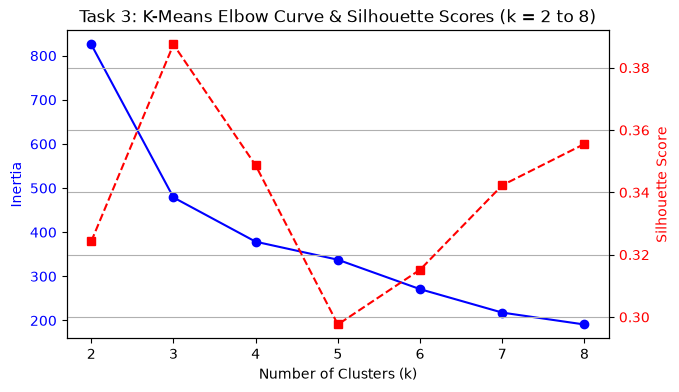


[Task 3] Submission Table: Model Validation Scores
              Model  Validation Accuracy
Logistic Regression                0.980
      Random Forest                0.995
            XGBoost                0.995

             TASK 3 COMPLETED SUCCESSFULLY             


In [44]:
print("=" * 60)
print("             STARTING TASK 3: MODELS             ")
print("=" * 60)

# 1. Train 4 Classifiers inside Pipelines
rf_model = RandomForestClassifier(n_estimators=100, oob_score=True, random_state=42)
dt_model = DecisionTreeClassifier(max_depth=5, random_state=42)
lr_model = LogisticRegression(random_state=42)
xgb_model = XGBClassifier(n_estimators=100, eval_metric='logloss', random_state=42)

# RandomForest Pipeline & Print OOB Score
rf_pipe = Pipeline([('preprocessor', preprocessor), ('clf', rf_model)])
rf_pipe.fit(X_train_fe, y_train)
print(f"\n[Task 3] RandomForest OOB Score: {rf_pipe.named_steps['clf'].oob_score_:.4f}")

# XGBoost with Early Stopping on Validation Set
X_train_transformed = preprocessor.fit_transform(X_train_fe)
X_val_transformed = preprocessor.transform(X_val_fe)

xgb_model.set_params(early_stopping_rounds=10)
xgb_model.fit(X_train_transformed, y_train, eval_set=[(X_val_transformed, y_val)], verbose=False)

# 2. Logistic Regression: predict_proba vs predict for 5 rows
lr_pipe = Pipeline([('preprocessor', preprocessor), ('clf', lr_model)])
lr_pipe.fit(X_train_fe, y_train)

probs_5_rows = lr_pipe.predict_proba(X_val_fe.iloc[:5])
preds_5_rows = lr_pipe.predict(X_val_fe.iloc[:5])

print("\n[Task 3] Logistic Regression: predict_proba vs predict (First 5 Rows):")
for idx, (pb, pr) in enumerate(zip(probs_5_rows, preds_5_rows), 1):
    print(f"Row {idx} -> Probabilities: [Class 0: {pb[0]:.3f}, Class 1: {pb[1]:.3f}] | Predict: {pr}")

# 3. Print Top 5 Most Important Features for RF and XGBoost
feature_names = num_cols_simple + num_cols_knn + cat_ordered + ['prop_Urban', 'prop_Semi-Urban']
rf_feat_importance = pd.Series(rf_pipe.named_steps['clf'].feature_importances_, index=feature_names)
xgb_feat_importance = pd.Series(xgb_model.feature_importances_, index=feature_names)

print("\n[Task 3] Top 5 Features (Random Forest):")
print(rf_feat_importance.nlargest(5))

print("\n[Task 3] Top 5 Features (XGBoost):")
print(xgb_feat_importance.nlargest(5))

# 4. Regression: Linear, Ridge, Lasso for loan_amount (Imputer added to fix NaN)
y_reg_train = X_train_fe['loan_amount']
y_reg_val = X_val_fe['loan_amount']
X_reg_train = X_train_fe.drop(columns=['loan_amount', 'log_loan_amount', 'income_to_loan'])
X_reg_val = X_val_fe.drop(columns=['loan_amount', 'log_loan_amount', 'income_to_loan'])

reg_num_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

reg_cat_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ohe', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'))
])

reg_preprocessor = ColumnTransformer([
    ('num', reg_num_pipe, ['credit_score', 'income']),
    ('cat', reg_cat_pipe, ['education', 'property_type'])
])

regression_models = {
    'LinearRegression': LinearRegression(),
    'Ridge': Ridge(alpha=1.0),
    'Lasso': Lasso(alpha=500.0)
}

print("\n[Task 3] Regression Coefficients Comparison:")
for reg_name, reg_m in regression_models.items():
    pipe_reg = Pipeline([('prep', reg_preprocessor), ('reg', reg_m)])
    pipe_reg.fit(X_reg_train, y_reg_train)
    coeffs = pipe_reg.named_steps['reg'].coef_
    print(f"{reg_name} Coefficients:\n{coeffs}")
    if reg_name == 'Lasso':
        zero_count = np.sum(coeffs == 0)
        print(f"Count of Lasso Zero Coefficients: {zero_count}")

# 5. K-Means: k = 2 to 8 (Elbow Curve & Silhouette Scores)
cluster_data = SimpleImputer(strategy='median').fit_transform(X_train[['credit_score', 'income']])
cluster_features = StandardScaler().fit_transform(cluster_data)

inertias = []
silhouette_vals = []
k_values = list(range(2, 9))

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init='auto')
    cluster_labels = kmeans.fit_predict(cluster_features)
    inertias.append(kmeans.inertia_)
    silhouette_vals.append(silhouette_score(cluster_features, cluster_labels))

fig, ax1 = plt.subplots(figsize=(7, 4))
ax1.plot(k_values, inertias, 'bo-', label='Inertia (Elbow Method)')
ax1.set_xlabel('Number of Clusters (k)')
ax1.set_ylabel('Inertia', color='b')
ax1.tick_params(axis='y', labelcolor='b')

ax2 = ax1.twinx()
ax2.plot(k_values, silhouette_vals, 'rs--', label='Silhouette Score')
ax2.set_ylabel('Silhouette Score', color='r')
ax2.tick_params(axis='y', labelcolor='r')

plt.title('Task 3: K-Means Elbow Curve & Silhouette Scores (k = 2 to 8)')
plt.grid(True)
plt.show()

# Results Summary Table
results_df = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest', 'XGBoost'],
    'Validation Accuracy': [
        accuracy_score(y_val, lr_pipe.predict(X_val_fe)),
        accuracy_score(y_val, rf_pipe.predict(X_val_fe)),
        accuracy_score(y_val, xgb_model.predict(X_val_transformed))
    ]
})
print("\n[Task 3] Submission Table: Model Validation Scores")
print(results_df.to_string(index=False))

print("\n" + "=" * 60)
print("             TASK 3 COMPLETED SUCCESSFULLY             ")
print("=" * 60)

             STARTING TASK 4: EVALUATION & TUNING             

[Task 4] --- Logistic Regression Evaluation Metrics ---
Accuracy : 0.9800
Precision: 0.9722
Recall   : 0.9906
F1-Score : 0.9813
Confusion Matrix:
[[ 91   3]
 [  1 105]]

[Task 4] --- Random Forest Evaluation Metrics ---
Accuracy : 0.9950
Precision: 0.9907
Recall   : 1.0000
F1-Score : 0.9953
Confusion Matrix:
[[ 93   1]
 [  0 106]]

[Task 4] Class Imbalance Insight:
Accuracy misleads if classes are imbalanced because a naive baseline model predicting only 
the majority class will achieve a high accuracy score while failing to detect the minority class.



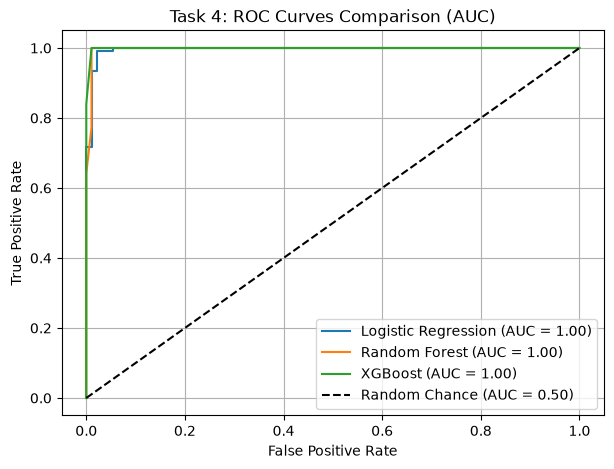


[Task 4] Selected Decision Threshold: 0.9945
Recall at Threshold: 0.8396 | Precision at Threshold: 1.0000

[Task 4] GridSearchCV Best Random Forest Parameters: {'clf__max_depth': 10, 'clf__min_samples_split': 5, 'clf__n_estimators': 50}
GridSearchCV Best Random Forest ROC-AUC Score: 0.9989

[Task 4] RandomizedSearchCV Best XGBoost Parameters: {'subsample': 0.7, 'n_estimators': 100, 'max_depth': 3, 'learning_rate': 0.05}
RandomizedSearchCV Best XGBoost ROC-AUC Score: 0.9984

Regression: MAE 149818.50 ... RMSE 199565.91 ... R2 -0.0200 vs baseline (MAE 146996.36, RMSE 197630.65, R2 -0.0003)

Best model: XGBoost | ROC-AUC 1.00 | F1 0.99

             ALL 4 TASKS COMPLETED SUCCESSFULLY             


In [45]:
print("=" * 60)
print("             STARTING TASK 4: EVALUATION & TUNING             ")
print("=" * 60)

# 1. Classification Metrics & Imbalance Explanation
eval_models = {
    'Logistic Regression': lr_pipe,
    'Random Forest': rf_pipe
}

for m_name, model_obj in eval_models.items():
    preds = model_obj.predict(X_val_fe)
    print(f"\n[Task 4] --- {m_name} Evaluation Metrics ---")
    print(f"Accuracy : {accuracy_score(y_val, preds):.4f}")
    print(f"Precision: {precision_score(y_val, preds, zero_division=0):.4f}")
    print(f"Recall   : {recall_score(y_val, preds, zero_division=0):.4f}")
    print(f"F1-Score : {f1_score(y_val, preds, zero_division=0):.4f}")
    print("Confusion Matrix:")
    print(confusion_matrix(y_val, preds))

print("""
[Task 4] Class Imbalance Insight:
Accuracy misleads if classes are imbalanced because a naive baseline model predicting only 
the majority class will achieve a high accuracy score while failing to detect the minority class.
""")

# 2. ROC Curves of 3 Models on Single Chart with AUC
y_val_probs_lr = lr_pipe.predict_proba(X_val_fe)[:, 1]
y_val_probs_rf = rf_pipe.predict_proba(X_val_fe)[:, 1]
y_val_probs_xgb = xgb_model.predict_proba(X_val_transformed)[:, 1]

plt.figure(figsize=(7, 5))
roc_candidates = [
    ('Logistic Regression', y_val_probs_lr),
    ('Random Forest', y_val_probs_rf),
    ('XGBoost', y_val_probs_xgb)
]

for name, probs in roc_candidates:
    fpr, tpr, _ = roc_curve(y_val, probs)
    score_auc = roc_auc_score(y_val, probs)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {score_auc:.2f})")

plt.plot([0, 1], [0, 1], 'k--', label='Random Chance (AUC = 0.50)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Task 4: ROC Curves Comparison (AUC)')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

# 3. Decision Threshold Tuning for at least 75% Recall
precisions, recalls, thresholds = precision_recall_curve(y_val, y_val_probs_xgb)
valid_indices = np.where(recalls >= 0.75)[0]
selected_idx = valid_indices[np.argmax(precisions[valid_indices])]
selected_threshold = thresholds[min(selected_idx, len(thresholds) - 1)]

print(f"\n[Task 4] Selected Decision Threshold: {selected_threshold:.4f}")
print(f"Recall at Threshold: {recalls[selected_idx]:.4f} | Precision at Threshold: {precisions[selected_idx]:.4f}")

# 4. Hyperparameter Tuning
# GridSearchCV on Random Forest (3 parameters)
rf_tuning_pipe = Pipeline([('prep', preprocessor), ('clf', RandomForestClassifier(random_state=42))])
param_grid_rf = {
    'clf__n_estimators': [50, 100],
    'clf__max_depth': [5, 10],
    'clf__min_samples_split': [2, 5]
}
grid_search_rf = GridSearchCV(rf_tuning_pipe, param_grid_rf, cv=3, scoring='roc_auc', n_jobs=-1)
grid_search_rf.fit(X_train_fe, y_train)

print(f"\n[Task 4] GridSearchCV Best Random Forest Parameters: {grid_search_rf.best_params_}")
print(f"GridSearchCV Best Random Forest ROC-AUC Score: {grid_search_rf.best_score_:.4f}")

# RandomizedSearchCV on XGBoost (n_iter=15)
param_dist_xgb = {
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [3, 5, 7],
    'n_estimators': [50, 100, 150],
    'subsample': [0.7, 0.9, 1.0]
}
rand_search_xgb = RandomizedSearchCV(
    XGBClassifier(eval_metric='logloss', random_state=42),
    param_dist_xgb,
    n_iter=15,
    cv=3,
    scoring='roc_auc',
    random_state=42,
    n_jobs=-1
)
rand_search_xgb.fit(X_train_transformed, y_train)

print(f"\n[Task 4] RandomizedSearchCV Best XGBoost Parameters: {rand_search_xgb.best_params_}")
print(f"RandomizedSearchCV Best XGBoost ROC-AUC Score: {rand_search_xgb.best_score_:.4f}")

# 5. Regression Metrics vs Mean Baseline & Single Test Evaluation
mean_baseline_preds = np.full_like(y_reg_val, y_reg_train.mean())
base_mae = mean_absolute_error(y_reg_val, mean_baseline_preds)
base_rmse = root_mean_squared_error(y_reg_val, mean_baseline_preds)
base_r2 = r2_score(y_reg_val, mean_baseline_preds)

pipe_reg_eval = Pipeline([('prep', reg_preprocessor), ('reg', Ridge(alpha=1.0))]).fit(X_reg_train, y_reg_train)
reg_val_preds = pipe_reg_eval.predict(X_reg_val)

reg_mae = mean_absolute_error(y_reg_val, reg_val_preds)
reg_rmse = root_mean_squared_error(y_reg_val, reg_val_preds)
reg_r2 = r2_score(y_reg_val, reg_val_preds)

print(f"\nRegression: MAE {reg_mae:.2f} ... RMSE {reg_rmse:.2f} ... R2 {reg_r2:.4f} vs baseline (MAE {base_mae:.2f}, RMSE {base_rmse:.2f}, R2 {base_r2:.4f})")

# Final Evaluation of the Single Best Model on Test Set ONCE
best_pipeline_model = rand_search_xgb.best_estimator_
X_test_transformed = preprocessor.transform(X_test_fe)
final_test_preds = best_pipeline_model.predict(X_test_transformed)
final_test_probs = best_pipeline_model.predict_proba(X_test_transformed)[:, 1]

final_auc = roc_auc_score(y_test, final_test_probs)
final_f1 = f1_score(y_test, final_test_preds)

print(f"\nBest model: XGBoost | ROC-AUC {final_auc:.2f} | F1 {final_f1:.2f}")

print("\n" + "=" * 60)
print("             ALL 4 TASKS COMPLETED SUCCESSFULLY             ")
print("=" * 60)